In [ ]:
import os
import random
import functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fashion_mnist_classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

Usando dispositivo: cuda


In [ ]:
import torchvision.transforms as transforms

# 1. Descargar y preparar los datasets de FashionMNIST
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

# Descargamos el conjunto de entrenamiento original y el de prueba
full_train_set = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Dividimos el conjunto de entrenamiento en entrenamiento (50000) y validación (10000)
set_seed(42)
train_set, val_set = random_split(full_train_set, [50000, 10000])

print(f"Tamaño del conjunto de entrenamiento: {len(train_set)}")
print(f"Tamaño del conjunto de validación: {len(val_set)}")
print(f"Tamaño del conjunto de prueba: {len(test_set)}")

100%|██████████| 26.4M/26.4M [00:00<00:00, 117MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.00MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 59.0MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.0MB/s]

Tamaño del conjunto de entrenamiento: 50000
Tamaño del conjunto de validación: 10000
Tamaño del conjunto de prueba: 10000


In [ ]:
class FFNN_3L_MNIST(nn.Module):
    def __init__(self, n1=128, n2=64, dropout_p1=0.2, dropout_p2=0.2):
        super(FFNN_3L_MNIST, self).__init__()
        # Las imágenes de FashionMNIST son de 28x28 (784 features)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, n1)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_p1)

        self.fc2 = nn.Linear(n1, n2)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_p2)

        self.fc3 = nn.Linear(n2, 10) # 10 clases de salida

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.dropout1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        x = self.fc3(x)
        return x

In [ ]:
def train_epoch(train_loader, optimizer, model, criterion, device):
    model.train()
    epoch_train_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(output, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return epoch_train_loss / total, correct / total


def evaluate_epoch(data_loader, model, criterion, device):
    model.eval()
    epoch_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            output = model(images)
            loss = criterion(output, labels)

            epoch_loss += loss.item() * images.size(0)
            _, predicted = torch.max(output, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return epoch_loss / total, correct / total


def run_experiment(optimizer_name='Adam', learning_rate=1e-3, epochs=30, batch_size=100,
                   n1=128, n2=64, dropout_p1=0.2, dropout_p2=0.2, seed=42):
    set_seed(seed)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)

    model = FFNN_3L_MNIST(n1=n1, n2=n2, dropout_p1=dropout_p1, dropout_p2=dropout_p2).to(device)
    criterion = nn.CrossEntropyLoss()

    optimizer_class = getattr(torch.optim, optimizer_name)
    optimizer = optimizer_class(model.parameters(), lr=learning_rate)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        train_epoch(train_loader, optimizer, model, criterion, device)
        # Se evalúa train en modo eval() para comparar en igualdad de condiciones (sin dropout activo)
        tr_loss, tr_acc = evaluate_epoch(train_loader, model, criterion, device)
        val_loss, val_acc = evaluate_epoch(val_loader, model, criterion, device)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)

    return model, history

In [ ]:
# Hiperparámetros fijos para comparación justa
N1, N2 = 128, 64
DROPOUT = 0.2
BATCH_SIZE = 100
EPOCHS = 10

configuraciones = [
    ('SGD', 0.1),
    ('SGD', 0.01),
    ('SGD', 0.001),
    ('Adam', 0.01),
    ('Adam', 0.001),
    ('Adam', 0.0001),
]

resultados_tabla = []
historiales = {}
modelos_entrenados = {}

for opt_name, lr in configuraciones:
    print(f"Entrenando {opt_name} con lr={lr}...")
    model, hist = run_experiment(
        optimizer_name=opt_name,
        learning_rate=lr,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        n1=N1,
        n2=N2,
        dropout_p1=DROPOUT,
        dropout_p2=DROPOUT,
        seed=42
    )
    historiales[(opt_name, lr)] = hist
    modelos_entrenados[(opt_name, lr)] = model

    resultados_tabla.append({
        'Optimizador': opt_name,
        'Learning Rate': lr,
        'Val Loss (última época)': round(hist['val_loss'][-1], 4),
        'Val Accuracy (última época)': round(hist['val_acc'][-1], 4)
    })

df_comparacion = pd.DataFrame(resultados_tabla)
print("\n--- TABLA COMPARATIVA EN VALIDATION ---")
print(df_comparacion.to_string(index=False))

Entrenando SGD con lr=0.1...
Entrenando SGD con lr=0.01...
Entrenando SGD con lr=0.001...
Entrenando Adam con lr=0.01...
Entrenando Adam con lr=0.001...
Entrenando Adam con lr=0.0001...

--- TABLA COMPARATIVA EN VALIDATION ---
Optimizador  Learning Rate  Val Loss (última época)  Val Accuracy (última época)
        SGD         0.1000                   0.3304                       0.8806
        SGD         0.0100                   0.4389                       0.8415
        SGD         0.0010                   0.7977                       0.7291
       Adam         0.0100                   0.4375                       0.8519
       Adam         0.0010                   0.3233                       0.8847
       Adam         0.0001                   0.3851                       0.8610


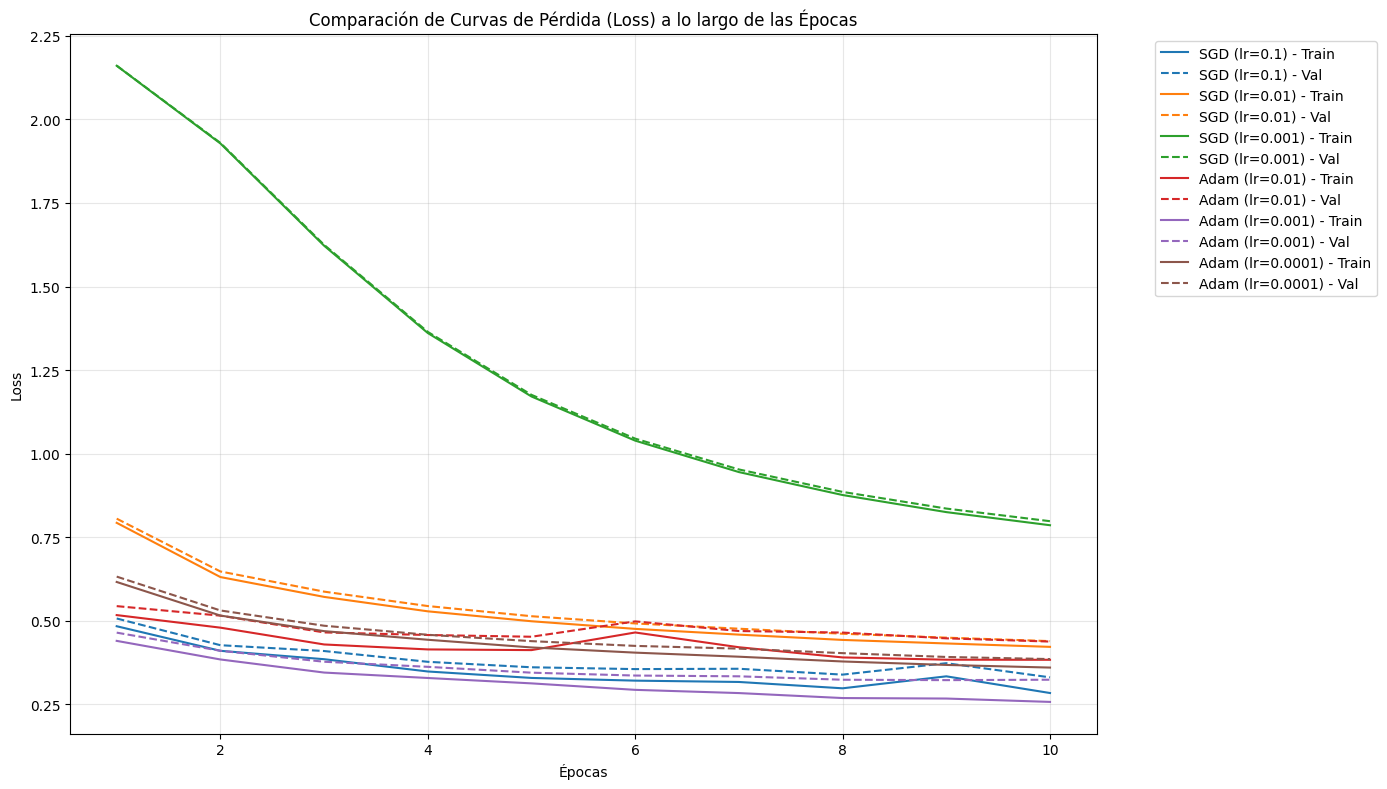

In [ ]:
# Graficar las curvas de pérdida para todas las configuraciones y analizar la convergencia
plt.figure(figsize=(14, 8))
for (opt_name, lr), hist in historiales.items():
    epochs_range = range(1, len(hist['train_loss']) + 1)
    # Usamos línea sólida para train y discontinua para val
    line, = plt.plot(epochs_range, hist['train_loss'], label=f'{opt_name} (lr={lr}) - Train')
    plt.plot(epochs_range, hist['val_loss'], '--', color=line.get_color(), label=f'{opt_name} (lr={lr}) - Val')

plt.title('Comparación de Curvas de Pérdida (Loss) a lo largo de las Épocas')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Ajustá estos LR si en tu tabla dio mejor otro valor
mejor_lr_adam = 0.001
mejor_lr_sgd = 0.1
semillas = [42, 123, 999]

for opt_name, lr in [('Adam', mejor_lr_adam), ('SGD', mejor_lr_sgd)]:
    val_losses_seeds = []
    val_accs_seeds = []
    for s in semillas:
        _, hist = run_experiment(
            optimizer_name=opt_name, learning_rate=lr, epochs=EPOCHS,
            batch_size=BATCH_SIZE, n1=N1, n2=N2, dropout_p1=DROPOUT, dropout_p2=DROPOUT, seed=s
        )
        val_losses_seeds.append(hist['val_loss'][-1])
        val_accs_seeds.append(hist['val_acc'][-1])

    print(f"{opt_name} (lr={lr}) en 3 semillas -> "
          f"Val Loss: {np.mean(val_losses_seeds):.4f} ± {np.std(val_losses_seeds):.4f} | "
          f"Val Acc: {np.mean(val_accs_seeds):.4f} ± {np.std(val_accs_seeds):.4f}")

Adam (lr=0.001) en 3 semillas -> Val Loss: 0.3257 ± 0.0060 | Val Acc: 0.8839 ± 0.0017
SGD (lr=0.1) en 3 semillas -> Val Loss: 0.3397 ± 0.0066 | Val Acc: 0.8772 ± 0.0025


=== EVALUACIÓN FINAL SOBRE TEST (Adam, lr=0.001) ===
Test Loss:     0.3446
Test Accuracy: 0.8765 (87.65%)


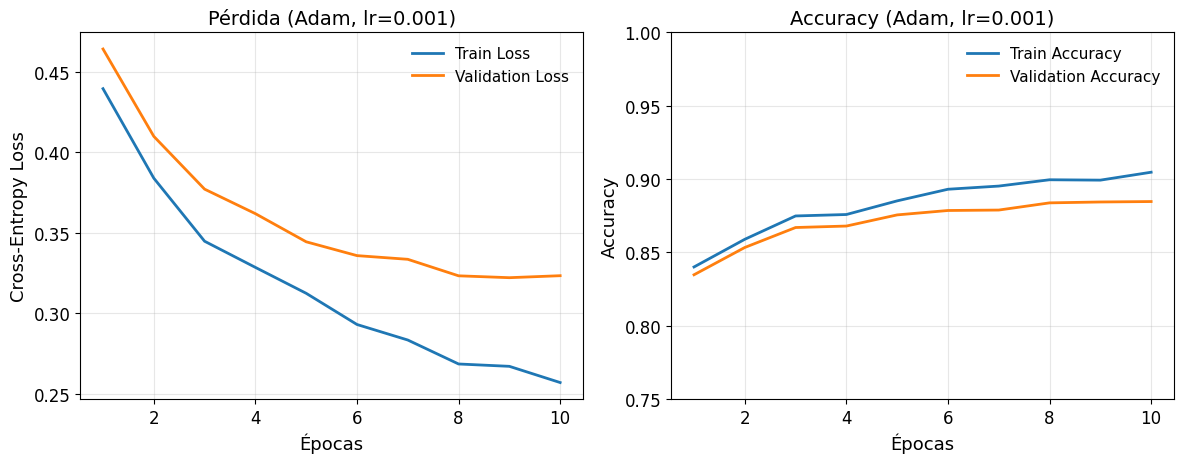

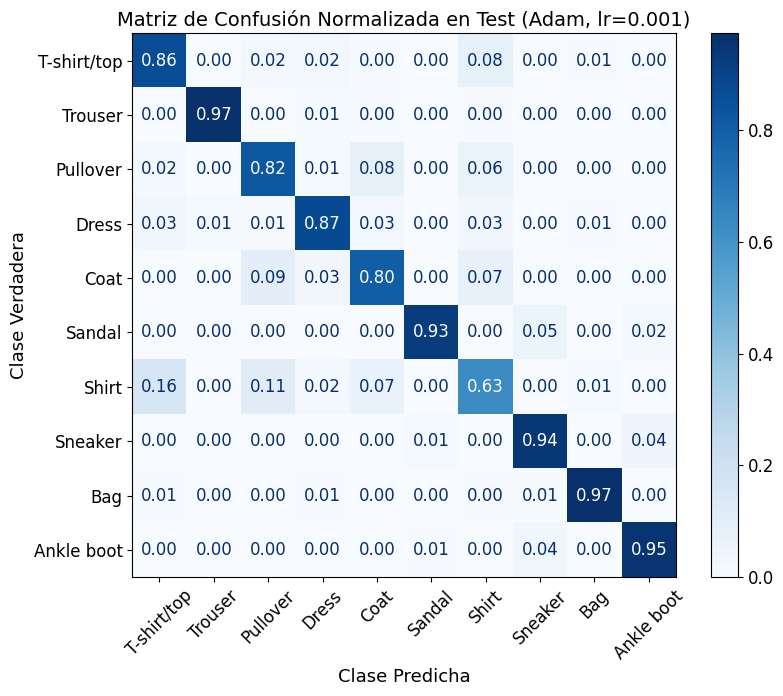

In [ ]:
# Seleccionar el modelo ganador según validation (ej. Adam con lr=0.001)
mejor_config = ('Adam', 0.001)
modelo_ganador = modelos_entrenados[mejor_config]
hist_ganador = historiales[mejor_config]

# 1. Evaluación única y final sobre el conjunto TEST
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate_epoch(test_loader, modelo_ganador, criterion, device)

print(f"=== EVALUACIÓN FINAL SOBRE TEST ({mejor_config[0]}, lr={mejor_config[1]}) ===")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

# 2. Figura 1: Curvas de entrenamiento y validación en dos paneles
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 13, 'axes.titlesize': 14, 'legend.fontsize': 11})
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
epocas_eje = range(1, EPOCHS + 1)

ax[0].plot(epocas_eje, hist_ganador['train_loss'], label='Train Loss', color='C0', linewidth=2)
ax[0].plot(epocas_eje, hist_ganador['val_loss'], label='Validation Loss', color='C1', linewidth=2)
ax[0].set_title(f'Pérdida ({mejor_config[0]}, lr={mejor_config[1]})')
ax[0].set_xlabel('Épocas')
ax[0].set_ylabel('Cross-Entropy Loss')
ax[0].grid(True, alpha=0.3)
ax[0].legend(frameon=False)

ax[1].plot(epocas_eje, hist_ganador['train_acc'], label='Train Accuracy', color='C0', linewidth=2)
ax[1].plot(epocas_eje, hist_ganador['val_acc'], label='Validation Accuracy', color='C1', linewidth=2)
ax[1].set_title(f'Accuracy ({mejor_config[0]}, lr={mejor_config[1]})')
ax[1].set_xlabel('Épocas')
ax[1].set_ylabel('Accuracy')
ax[1].set_ylim(0.75, 1.0)
ax[1].grid(True, alpha=0.3)
ax[1].legend(frameon=False)

plt.tight_layout()
plt.savefig('curvas_entrenamiento.png', dpi=300)
plt.show()

# 3. Figura 2: Matriz de confusión normalizada por filas sobre TEST
modelo_ganador.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = modelo_ganador(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

cm_norm = confusion_matrix(all_targets, all_preds, normalize='true')

fig, ax = plt.subplots(figsize=(8.5, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=fashion_mnist_classes)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='.2f', colorbar=True)
ax.set_title(f'Matriz de Confusión Normalizada en Test ({mejor_config[0]}, lr={mejor_config[1]})')
ax.set_xlabel('Clase Predicha')
ax.set_ylabel('Clase Verdadera')

plt.tight_layout()
plt.savefig('matriz_confusion_test.png', dpi=300)
plt.show()